# 02 — Preprocessing đã hoàn tất

**Run All** để xem dữ liệu đầu vào, các bước xử lý, split và kiểm chứng artifact.
Kết quả chính luôn hiển thị với `RUN_HISTORICAL_INSPECTION=False`.
Các phân tích trước phê duyệt nằm ở phụ lục tùy chọn và báo cáo đã lưu.

## 1. Runtime dùng chung Colab/Drive

Runtime chung Colab/Drive: [hướng dẫn duy nhất](../docs/phase3_colab.md). Cấu hình ở `configs/runtime.json`; source từ Drive, thực thi trong `/content`. Outputs đã lưu là lịch sử, không phải bằng chứng đã chạy trên Colab.

In [3]:
import runpy, platform
from pathlib import Path
if platform.system() != 'Linux' or not Path('/content').is_dir():
    raise RuntimeError('Chọn Google Colab kernel; /content phải là ổ tạm của runtime.')
DRIVE_ROOT = Path('/content/drive/MyDrive/ML_Projects/disease-prediction-ml')  # Locator sinh từ configs/runtime.json
entry = DRIVE_ROOT / 'src/data/colab_runtime.py'
if not entry.is_file():
    raise FileNotFoundError(f'Không thấy {entry}. Mount Drive và Publish source bằng prepare_colab_source.ps1; không upload script riêng.')
EXPECTED_RUNTIME_PAYLOAD = globals().get('EXPECTED_RUNTIME_PAYLOAD') or input('Paste RUNTIME_PAYLOAD_SHA256 from local Publish: ').strip()
RUNTIME = runpy.run_path(str(entry))['bootstrap_runtime'](DRIVE_ROOT, phase=2, expected_payload_sha256=EXPECTED_RUNTIME_PAYLOAD)
ROOT, runtime_paths = RUNTIME.paths.project_root, RUNTIME.paths
RUN_HISTORICAL_INSPECTION = False

Stage A PASS | Colab Python 3.13.16 | Drive=/content/drive/MyDrive/ML_Projects/disease-prediction-ml | runtime/Drive read-write OK
Stage B PASS | imports=/content/disease-prediction-ml-runtime | source fingerprint=95b01d6ea67d68f9bbc48b647ca15b3c38219baac15639ae78637f184806bd61


## 2. Nạp dữ liệu và xác thực

Bootstrap hiện có kiểm source trước khi import; mount chỉ theo yêu cầu và khả năng của runtime.
Output root phải chứa `data/processed/` và `artifacts/metadata/phase2/` đã khóa.
Thiếu storage/artifact sẽ dừng để chỉnh đường dẫn, không tạo lại dataset.

In [4]:
import json
import sys
try:
    import numpy as np
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        f"Thiếu {exc.name}. Cài chủ động: %pip install -r {str(ROOT / 'requirements-notebooks.txt')!r}; restart kernel."
    ) from exc
from IPython.display import display, Markdown
from src.data.io import read_config
from src.data.loader import dataset_path, prepare_dataset, load_dataset, sha256_file
from src.data.paths import OutputPaths
from src.data.preprocessing import read_phase2_policy, validate_raw_frame, preprocess_dataset, export_preprocessed

phase2_policy = read_phase2_policy(ROOT)
config = read_config(ROOT)
if config["target"] != phase2_policy["target"]:
    raise ValueError("Nhãn Phase 1/Phase 2 không khớp.")
OUTPUT = OutputPaths(runtime_paths.output_root)
manifest_path = OUTPUT.metadata_dir / "phase2/dataset_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError(
        f"Không thấy bộ Phase 2 đã khóa: {manifest_path}. Kiểm tra output root/Drive và đồng bộ "
        "data/processed/ cùng artifacts/metadata/phase2/. Notebook này không tái tạo bộ dữ liệu đã khóa."
    )
locked_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
source_path = dataset_path(runtime_paths, config)
source_sha = sha256_file(source_path)
assert source_sha == locked_manifest["raw"]["sha256"], "CSV không khớp nguồn của bộ đã khóa."
read_path = prepare_dataset(runtime_paths, source_path)
assert sha256_file(read_path) == source_sha, "Cache khác CSV nguồn."
df = load_dataset(read_path, config["target"])
validate_raw_frame(df, phase2_policy)
print(f"CSV: {source_path.name} | runtime dữ liệu: {runtime_paths.runtime}")
display(pd.DataFrame([{"Bản ghi raw": len(df), "Lớp bệnh raw": df[config["target"]].nunique(),
                       "Triệu chứng raw": df.shape[1] - 1}]))

CSV: Disease and symptoms dataset.csv | runtime dữ liệu: colab


,Bản ghi raw,Lớp bệnh raw,Triệu chứng raw
0,246945,773,377


## 3. Pipeline preprocessing đã duyệt

Xác thực raw → bỏ `regurgitation`/`regurgitation.1` → dedup **vector còn lại + nhãn** →
đếm vector độc lập/lớp → giữ lớp ≥10 → group split 70/15/15, seed 42.
Hai cột bị loại vì không xác minh được cách phân biệt khi thu nhận triệu chứng.
Giữ các nhãn khác nhau của cùng vector. Tính lại trong RAM để đối chiếu bộ đã khóa;
giữ nguyên raw và cột hằng. `VarianceThreshold(0)` chỉ fit trên train trong Phase 3.

In [5]:
print("[3/5] Bỏ cột → exact dedup → ≥10 vector/lớp → group split seed 42...", flush=True)
finalized = preprocess_dataset(df, phase2_policy)
labels = {
    "validated_raw": "1. Xác thực raw",
    "removed_ambiguous_features": "2. Bỏ hai cột regurgitation",
    "exact_dedup_remaining_vector_and_label": "3. Dedup vector còn lại + nhãn",
    "recalculated_independent_vectors_per_class": "4. Đếm lại vector mỗi bệnh",
    "eligible_classes_after_schema_and_dedup": "5. Giữ bệnh ≥10 vector",
    "generated_remaining_vector_groups": "6. Tạo group theo vector còn lại",
    "validated_final_split_total": "7. Hoàn tất và kiểm chứng split",
}
steps_view = finalized["steps"].rename(columns={"step": "Bước", "records": "Bản ghi", "classes": "Lớp bệnh", "symptom_features": "Triệu chứng"})
steps_view["Bước"] = steps_view["Bước"].map(labels)
display(steps_view)
print(f"Kết quả: {len(finalized['data']):,} bản ghi | {len(finalized['classes'])} lớp bệnh | "
      f"{len(finalized['features'])} triệu chứng trước variance removal.")


[3/5] Bỏ cột → exact dedup → ≥10 vector/lớp → group split seed 42...


,Bước,Bản ghi,Lớp bệnh,Triệu chứng
0,1. Xác thực raw,246945,773,377
1,2. Bỏ hai cột regurgitation,246945,773,375
2,3. Dedup vector còn lại + nhãn,188161,773,375
3,4. Đếm lại vector mỗi bệnh,188161,773,375
4,5. Giữ bệnh ≥10 vector,187434,587,375
5,6. Tạo group theo vector còn lại,187434,587,375
6,7. Hoàn tất và kiểm chứng split,187434,587,375


Kết quả: 187,434 bản ghi | 587 lớp bệnh | 375 triệu chứng trước variance removal.


## 4. Kiểm chứng split và trực quan kết quả

Độ phủ lớp không bảo đảm metric từng bệnh ổn định; số liệu test ở đây chỉ phục vụ kiểm tra toàn vẹn.

,Tập,Bản ghi,Tỷ lệ %,Group,Lớp bệnh
0,train,131248,70.0236,117211,587
1,validation,28120,15.0026,25127,587
2,test,28066,14.9738,25128,587


,Kiểm tra,Kết quả
0,"Exact duplicate (vector, nhãn)",0
1,Giao group giữa từng cặp split,"{'train / validation': 0, 'train / test': 0, '..."
2,Giao vector (equality độc lập),"{'train / validation': 0, 'train / test': 0, '..."
3,Lớp vắng train/validation/test,"{'train': 0, 'validation': 0, 'test': 0}"
4,Tái lập assignment/support seed 42,True


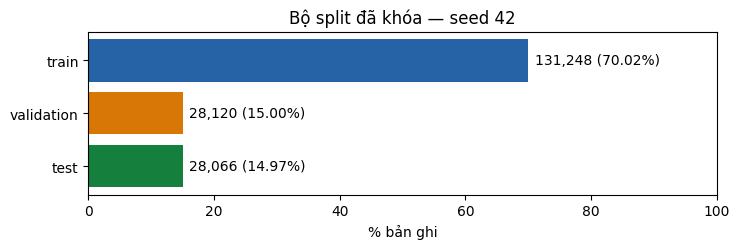

Nhóm nhiều nhãn được giữ: 12,728. Lớp chỉ có 1 vector validation/test: 33/41.


In [6]:
summary = finalized["split_summary"].rename(columns={"split": "Tập", "dedup_records": "Bản ghi",
    "pct_records": "Tỷ lệ %", "groups": "Group", "classes": "Lớp bệnh"})
display(summary.round({"Tỷ lệ %": 4}))
v = finalized["validation"]
checks = [
    {"Kiểm tra": "Exact duplicate (vector, nhãn)", "Kết quả": v["exact_duplicate_rows"]},
    {"Kiểm tra": "Giao group giữa từng cặp split", "Kết quả": str(v["group_overlaps"])},
    {"Kiểm tra": "Giao vector (equality độc lập)", "Kết quả": str(v["symptom_vector_overlaps"])},
    {"Kiểm tra": "Lớp vắng train/validation/test", "Kết quả": str({k: len(x) for k, x in v["missing_classes"].items()})},
    {"Kiểm tra": "Tái lập assignment/support seed 42", "Kết quả": v["deterministic_assignment_recomputed"]},
]
display(pd.DataFrame(checks))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.barh(summary["Tập"], summary["Tỷ lệ %"], color=["#2563a6", "#d97706", "#15803d"])
for name, records, percentage in summary[["Tập", "Bản ghi", "Tỷ lệ %"]].itertuples(index=False, name=None):
    ax.text(percentage + 1, name, f"{records:,} ({percentage:.2f}%)", va="center")
ax.set(xlabel="% bản ghi", xlim=(0, 100), title="Bộ split đã khóa — seed 42")
ax.invert_yaxis()
fig.tight_layout()
display(fig)
plt.close(fig)
print(f"Nhóm nhiều nhãn được giữ: {v['conflicting_groups_preserved']:,}. "
      f"Lớp chỉ có 1 vector validation/test: {v['singleton_validation_classes']}/{v['singleton_test_classes']}.")

## 5. Kiểm chứng artifact và tổng kết

Đối chiếu dữ liệu vừa tính với schema, mapping, assignment và checksum đã lưu; tái sử dụng nguyên bộ file.

In [7]:
# Manifest phải tồn tại; export_preprocessed chỉ kiểm chứng/tái sử dụng bộ đã khóa.
manifest_sha_before = sha256_file(manifest_path)
manifest = export_preprocessed(finalized, source_path, OUTPUT, expected_source_sha256=source_sha)
assert sha256_file(manifest_path) == manifest_sha_before, "Manifest đã khóa thay đổi."
assert sha256_file(source_path) == source_sha, "Raw thay đổi."
assert finalized["processed_sha256"] == manifest["processed"]["sha256"]
print(f"ĐÃ TÁI SỬ DỤNG bộ split đã khóa; {len(manifest['files'])} checksum artifact hợp lệ.")
display(pd.DataFrame([
    {"Artifact": "Train / validation / test", "Vị trí": str(OUTPUT.processed_dir)},
    {"Artifact": "Schema, label mapping, policy, assignment và split metadata", "Vị trí": str(OUTPUT.metadata_dir / "phase2")},
    {"Artifact": "Manifest", "Vị trí": str(manifest_path)},
]))
print("SHA-256 raw:", manifest["raw"]["sha256"])
print("Fingerprint processed:", manifest["processed"]["sha256"])
display(Markdown("**Phase 2 đã kiểm chứng, sẵn sàng đọc train/validation bằng `load_final_split()`.** "
                 "Test chỉ dùng đánh giá cuối. Chưa fit transformer, huấn luyện mô hình hoặc triển khai chatbot."))

ĐÃ TÁI SỬ DỤNG bộ split đã khóa; 8 checksum artifact hợp lệ.


,Artifact,Vị trí
0,Train / validation / test,/content/drive/MyDrive/ML_Projects/disease-pre...
1,"Schema, label mapping, policy, assignment và s...",/content/drive/MyDrive/ML_Projects/disease-pre...
2,Manifest,/content/drive/MyDrive/ML_Projects/disease-pre...


SHA-256 raw: 8de90603ebada467fc2703db2ee4292856e52d64e94982ef926df22fa0c21320
Fingerprint processed: afde00ce35bf4fd31c9c76edcc3c8b64104e53fb81dd98d4a56d7b3a884b16b3


**Phase 2 đã kiểm chứng, sẵn sàng đọc train/validation bằng `load_final_split()`.** Test chỉ dùng đánh giá cuối. Chưa fit transformer, huấn luyện mô hình hoặc triển khai chatbot.

### Phụ lục tùy chọn — lịch sử trước phê duyệt

Mặc định tắt. Chi tiết đã lưu trong [báo cáo Phase 2](../reports/preprocessing_decision_review.md),
[bảng lịch sử](../reports/tables/) và [hình so sánh ngưỡng](../reports/figures/preprocessing_threshold_comparison.png).
Cell dưới tái hiện phân tích trên schema gốc khi bật cờ; các mốc ≥5/≥15 là đối chiếu lịch sử.
**Quyết định cuối đã duyệt:** bỏ hai cột mơ hồ, dedup sau bỏ cột, ngưỡng ≥10 và split seed 42.

In [8]:
if RUN_HISTORICAL_INSPECTION:
    from src.data.audit import audit_dataset
    from src.data.preprocessing_inspection import (
        inspect_header, inspect_regurgitation, class_eligibility, group_split_feasibility,
        threshold_split_comparison, both_features_removal_impact, threshold_comparison_figure,
    )
    audit = audit_dataset(df, config)
    s = audit["summary"]
    header = inspect_header(read_path)
    reference = {"rows": 246945, "classes": 773, "features": 377,
                 "constant_features": 49, "conflicting_pattern_groups": 12634,
                 "classes_with_lt5_patterns": 115}
    comparison = pd.DataFrame([{"metric": key, "phase1_reported": old,
                                "observed_now": s[key], "matches": old == s[key]}
                               for key, old in reference.items()])
    display(comparison)
    if not comparison["matches"].all():
        print("Dữ liệu khác mốc Phase 1: dùng số đếm hiện tại; cần rà soát lại mọi quyết định.")

    pairs = audit["pattern_labels"]
    projected_dedup_rows = len(pairs)
    # Đối chiếu độc lập với equality trên toàn bộ dòng, không dựa riêng ID của audit.
    assert int(df.duplicated().sum()) == s["exact_duplicate_excess_rows"]
    assert projected_dedup_rows == len(df) - s["exact_duplicate_excess_rows"]
    assert int(pairs["rows"].sum()) == len(df)
    display(pd.DataFrame([{
        "raw_rows": len(df), "exact_duplicate_excess_rows": s["exact_duplicate_excess_rows"],
        "rows_in_duplicate_groups_including_first": s["rows_in_exact_duplicate_groups"],
        "hypothetical_rows_after_dedup": projected_dedup_rows,
        "unique_full_vectors": s["unique_feature_vectors"],
        "conflicting_full_vectors": s["conflicting_pattern_groups"],
    }]))

    reg = inspect_regurgitation(df, audit, config["target"])
    print("Header nguyên văn:", header)
    display(pd.DataFrame([reg["counts"]]))
    display(reg["disease_support"])
    assert reg["counts"]["matching_rows"] + reg["counts"]["differing_rows"] == len(df)
    assert reg["counts"]["regurgitation_ones"] + reg["counts"]["regurgitation.1_ones"] == (
        2 * reg["counts"]["both_ones"] + reg["counts"]["exactly_one"])
    display(reg["projections"])

    eligibility, inventory = class_eligibility(pairs, len(df))
    assert inventory["unique_vectors"].sum() == projected_dedup_rows
    assert (inventory["unique_vectors"] < 5).sum() == s["classes_with_lt5_patterns"]
    display(eligibility.round(4))
    CANDIDATE_MINIMUM = 5  # Mốc rà soát ban đầu; giữ để tái hiện 5 CSV lịch sử.
    print("Lịch sử dùng mốc ≥5; chính sách đã duyệt ở trên dùng ≥10 sau bỏ hai cột.")

    split = group_split_feasibility(pairs, minimum=CANDIDATE_MINIMUM, seed=config["seed"])
    display(split["summary"].round(4))
    print("Lớp vắng ở từng tập:", json.dumps(split["missing_classes"], ensure_ascii=False))
    print("Giao group từng cặp:", split["overlaps"])
    print("Số chuyển group để bảo vệ độ phủ:", split["repairs"])
    assert not any(split["overlaps"].values())
    candidate = eligibility.loc[eligibility["min_unique_vectors"] == CANDIDATE_MINIMUM].iloc[0]
    assert split["summary"]["dedup_records"].sum() == candidate["dedup_records"]
    class_support = inventory.merge(split["class_support"].drop(columns="unique_vectors"),
                                    on="disease", how="left")
    class_support["eligible_candidate"] = class_support["unique_vectors"] >= CANDIDATE_MINIMUM
    for name in ["train", "validation", "test"]:
        class_support[name] = class_support[name].fillna(0).astype(int)
    display(class_support.head(15))
    display(split["class_support"][["train", "validation", "test"]].describe())
    print("Số lớp chỉ có 1 vector ở validation/test:", {
        name: int(split["class_support"][name].eq(1).sum()) for name in ["validation", "test"]})
    print("Đủ mặt lớp chưa chứng minh đánh giá ổn định; toàn bộ support lớp sẽ lưu dạng tổng hợp.")

    constants = audit["features"].loc[audit["features"]["constant"], ["feature", "min", "max", "present_count"]]
    assert len(constants) == s["constant_features"]
    print(f"Xác nhận {len(constants)} cột hằng; các giá trị thực tế:")
    with pd.option_context("display.max_rows", None):
        display(constants)

    FINAL_REVIEW_SEED = 42
    threshold_analysis = threshold_split_comparison(pairs, len(df), thresholds=(1, 3, 5, 10, 15), seed=FINAL_REVIEW_SEED)
    threshold_table = threshold_analysis["comparison"]
    columns = ["min_unique_vectors", "retained_classes", "excluded_classes", "dedup_records",
               "pct_of_dedup_records", "singleton_validation_classes", "singleton_test_classes",
               "missing_train_classes", "missing_validation_classes", "missing_test_classes"]
    display(threshold_table[columns].round(4))
    for minimum, probe in threshold_analysis["splits"].items():
        print(f"Ngưỡng ≥{minimum}: giao group {probe['overlaps']}; lớp vắng "
              f"train/val/test = { {k: len(v) for k, v in probe['missing_classes'].items()} }")
        assert not any(probe["overlaps"].values())
    # Lựa chọn phân tích: cân bằng độ phủ bệnh và support độc lập, không dùng model score.
    RECOMMENDED_MINIMUM = 10
    candidate_split = threshold_analysis["splits"][RECOMMENDED_MINIMUM]
    display(candidate_split["summary"].round(4))
    print("Lớp vắng ứng viên:", candidate_split["missing_classes"])
    import matplotlib.pyplot as plt
    import inspect, tempfile
    if "save" in inspect.signature(threshold_comparison_figure).parameters:
        fig, _ = threshold_comparison_figure(threshold_analysis, OUTPUT, recommended=RECOMMENDED_MINIMUM, save=False)
    else:
        # ZIP Phase 2 cũ chưa có save=False: preview ở ổ tạm local, không ghi đè báo cáo.
        with tempfile.TemporaryDirectory(prefix="phase2-preview-") as preview_root:
            fig, _ = threshold_comparison_figure(
                threshold_analysis, OutputPaths(Path(preview_root)), recommended=RECOMMENDED_MINIMUM)
    display(fig)
    plt.close(fig)

    feature_impact = both_features_removal_impact(df, audit, config["target"], minimum=RECOMMENDED_MINIMUM)
    impact_summary = feature_impact["summary"]
    assert impact_summary["comparison_denominator_records"] == len(pairs)
    assert not impact_summary["class_filter_applied"]
    display(pd.DataFrame([{"metric": k, "value": v} for k, v in impact_summary.items()]))
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(feature_impact["class_impact"].round({"pct_vectors_lost": 2}))
    print("Toàn bộ tên bệnh liên quan:", feature_impact["associated_disease_names"])
    print("Lớp đủ ngưỡng trước đó nay không đủ:", feature_impact["lost_eligible_classes"])
    print("Lớp mới đủ ngưỡng:", feature_impact["gained_eligible_classes"])
    assert len(df) == s["rows"] and df.shape[1] == s["columns"]

    print("Phân tích lịch sử hoàn tất; bộ split và chính sách đã khóa giữ nguyên.")
else:
    print("Lịch sử đã tắt; kết quả chính nằm ở 5 mục trên. Bật RUN_HISTORICAL_INSPECTION=True và Run All nếu cần xem lại.")

Lịch sử đã tắt; kết quả chính nằm ở 5 mục trên. Bật RUN_HISTORICAL_INSPECTION=True và Run All nếu cần xem lại.
